# Phase 2 — Machine Learning
## Lesson 2.1.3: Understand Features, Targets, Datasets, and Labels

**Series:** AI & ML — Learn • Build • Grow  
**Module:** 2.1 — ML Fundamentals  
**Primary framework:** PyTorch  
**Environment:** Jupyter Notebook · CPU-friendly  
**Previous lesson:** 2.1.2 — Understand Supervised vs. Unsupervised Learning

---

## Why does this lesson matter?

In the previous lesson, we trained a small classifier using customer information. Before a model can learn, we need to be precise about what each piece of data represents.

Imagine one row describing one customer:

- How often does this customer visit?
- How much do they spend?
- What customer category are we trying to predict?

The first two values can be **features** (the model's inputs). The category is the **target** (the answer we want the model to learn to predict). All the examples together form a **dataset**. In a classification task, the known target category for an example is commonly called its **label**.

This notebook makes those ideas concrete and prepares data in a form PyTorch can consume. It does not yet teach data splitting, model evaluation, or a complete reusable pipeline; those come in later lessons.

## Learning objectives

By the end, you should be able to:

- explain what a dataset and one data example represent;
- identify rows, columns, features, targets, and labels;
- separate the input matrix `X` from the target `y`;
- distinguish classification labels from numerical regression targets;
- understand why an identifier is not automatically a useful feature;
- convert features and targets into PyTorch tensors;
- wrap tensors in a PyTorch `TensorDataset` and inspect a mini-batch.

> **Big idea:** Before choosing or training a model, decide exactly what information the model receives and what it is expected to predict.

## 1. Start with the customer dataset from Lesson 2.1.2

We will continue with the same teaching scenario: each row describes a customer using two numeric scores.

- `monthly_visit_score`: how frequently the customer visits, on a 0–10 teaching scale;
- `spending_score`: the customer's spending level, on a 0–10 teaching scale;
- `customer_segment`: a known category used as the target in our supervised classification example.

The data are synthetic so that everyone can reproduce the same experiment. The categories are created for teaching; real project labels need a trustworthy source such as reviewed examples or a clearly defined business rule.

## 2. Import libraries and make the example reproducible

We use:

- **pandas** to organize examples in a table;
- **Matplotlib** to visualize the data;
- **PyTorch** to convert the input and target values into tensors and prepare examples for a model.

All operations run on CPU. No NVIDIA GPU is required.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader

SEED = 21
torch.manual_seed(SEED)
np.random.seed(SEED)

DEVICE = torch.device("cpu")
CLASS_NAMES = ["Tier_A", "Tier_B", "Tier_C"]
CLASS_COLORS = {
    "Tier_A": "#38BDF8",
    "Tier_B": "#F59E0B",
    "Tier_C": "#A78BFA",
}

# Make output paths work when the notebook is launched from either
# the lesson_example folder or the project root.
CURRENT_DIR = Path.cwd()
if CURRENT_DIR.name == "notebooks":
    LESSON_DIR = CURRENT_DIR.parent
elif (CURRENT_DIR / "lesson_example").is_dir():
    LESSON_DIR = CURRENT_DIR / "lesson_example"
else:
    LESSON_DIR = CURRENT_DIR

OUTPUT_DIR = LESSON_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {DEVICE}")
print(f"Output directory: {OUTPUT_DIR.resolve()}")

PyTorch version: 2.15.0+cpu
Device: cpu
Output directory: D:\AI\Assignment\machine-learning\module1\phase-2-lesson-2.1.3-features-targets-datasets-labels\outputs


## 3. Create the examples

To keep continuity with Lesson 2.1.2, we recreate its three customer patterns with the same random seed and the same cluster centers. Each row will be one customer example.

For this lesson, the customer category is available so that we can practice supervised learning data preparation. Later, when we discuss unsupervised learning, we can leave this target column out and use only the feature columns.

In [2]:
centers = torch.tensor(
    [
        [2.0, 2.0],   # Tier_A
        [7.5, 2.7],   # Tier_B
        [6.2, 7.5],   # Tier_C
    ],
    dtype=torch.float32,
)

samples_per_group = 60
feature_noise = torch.tensor([0.65, 0.70], dtype=torch.float32)

feature_parts = []
label_parts = []
for class_id, center in enumerate(centers):
    points = center + torch.randn(samples_per_group, 2) * feature_noise
    points = points.clamp(0.0, 10.0)
    feature_parts.append(points)
    label_parts.append(torch.full((samples_per_group,), class_id, dtype=torch.long))

X_raw = torch.cat(feature_parts, dim=0).cpu().numpy()
y_ids = torch.cat(label_parts, dim=0).cpu().numpy()

# Convert the integer class IDs into readable category names.
labels_as_names = [CLASS_NAMES[class_id] for class_id in y_ids]

customer_df = pd.DataFrame(
    {
        "customer_id": [f"C{i:03d}" for i in range(1, len(X_raw) + 1)],
        "monthly_visit_score": X_raw[:, 0],
        "spending_score": X_raw[:, 1],
        "customer_segment": labels_as_names,
    }
)

print(f"Number of examples (rows): {len(customer_df)}")
print(f"Number of columns: {len(customer_df.columns)}")

Number of examples (rows): 180
Number of columns: 4


## 4. A dataset is a collection of examples

A **dataset** is an organized collection of examples (also called observations, records, or samples).

In this table:

- each **row** represents one customer example;
- each **column** represents one variable about that customer;
- each cell contains one value for that example and variable.

Look at the first few rows before we decide which columns should become model inputs and which column should be predicted.

In [3]:
display(customer_df.head(8).round(2))

,customer_id,monthly_visit_score,spending_score,customer_segment
0,C001,1.84,1.23,Tier_A
1,C002,2.10,2.12,Tier_A
2,C003,1.38,1.62,Tier_A
3,C004,2.78,2.67,Tier_A
4,C005,1.28,1.41,Tier_A
5,C006,2.00,2.16,Tier_A
6,C007,2.57,1.62,Tier_A
7,C008,1.81,2.68,Tier_A


### Read one row like a model builder

For customer `C001`, the row contains two scores and one category. The scores describe the customer. The category is the known answer for our classification task.

The `customer_id` helps us identify the record, but it is not automatically a useful signal for predicting the category. We will keep it for reference and leave it out of the model input.

## 5. Identify the features

A **feature** is an input variable used by a model to make a prediction.

For our task, we choose:

1. `monthly_visit_score`
2. `spending_score`

The feature matrix is conventionally named `X` (capital X). It contains one row per example and one column per feature.

In [4]:
FEATURE_COLUMNS = [
    "monthly_visit_score",
    "spending_score",
]

X_df = customer_df[FEATURE_COLUMNS].copy()

display(X_df.head().round(2))
print("Feature matrix shape:", X_df.shape)

,monthly_visit_score,spending_score
0,1.84,1.23
1,2.10,2.12
2,1.38,1.62
3,2.78,2.67
4,1.28,1.41


Feature matrix shape: (180, 2)


### What does the shape tell us?

A matrix shape is written as `(number of examples, number of features)`.

For example, `(180, 2)` means:

- 180 customer examples (rows);
- 2 input features (columns).

This is a simple but important check: the model must receive the feature columns we intended, not the ID or the answer column.

In [5]:
number_of_examples, number_of_features = X_df.shape
print(f"X has {number_of_examples} rows and {number_of_features} feature columns.")
print("Feature names:", FEATURE_COLUMNS)

X has 180 rows and 2 feature columns.
Feature names: ['monthly_visit_score', 'spending_score']


## 6. Identify the target

The **target** is the value we want the model to predict. It is conventionally named `y` (lowercase y).

Our question is: “Given a customer's visit and spending scores, which customer segment should the model predict?”

Therefore, `customer_segment` is the target column. We keep it separate from `X`; we must not accidentally give the known answer to the model as one of its input features.

In [6]:
TARGET_COLUMN = "customer_segment"
y_names = customer_df[TARGET_COLUMN].copy()

print("Target column:", TARGET_COLUMN)
display(y_names.head())
print("Target shape:", y_names.shape)

Target column: customer_segment


0    Tier_A
1    Tier_A
2    Tier_A
3    Tier_A
4    Tier_A
Name: customer_segment, dtype: str

Target shape: (180,)


### Put the pieces together: `X` and `y`

For supervised learning, each training example has:

- **input (`X`)**: the feature values;
- **target (`y`)**: the known answer associated with those feature values.

The rows of `X` and `y` must stay aligned. Row 0 in `X` and row 0 in `y` describe the same customer.

In [7]:
print("X shape:", X_df.shape)
print("y shape:", y_names.shape)

print("\nFirst example — model input:")
print(X_df.iloc[0].to_dict())

print("First example — known target:")
print(y_names.iloc[0])

X shape: (180, 2)
y shape: (180,)

First example — model input:
{'monthly_visit_score': 1.8449252843856812, 'spending_score': 1.2345874309539795}
First example — known target:
Tier_A


## 7. Visualize features and target together

The horizontal and vertical axes are the two features. The point color shows the target category.

The features describe each example; the target gives the known category we want a supervised classifier to learn to predict.

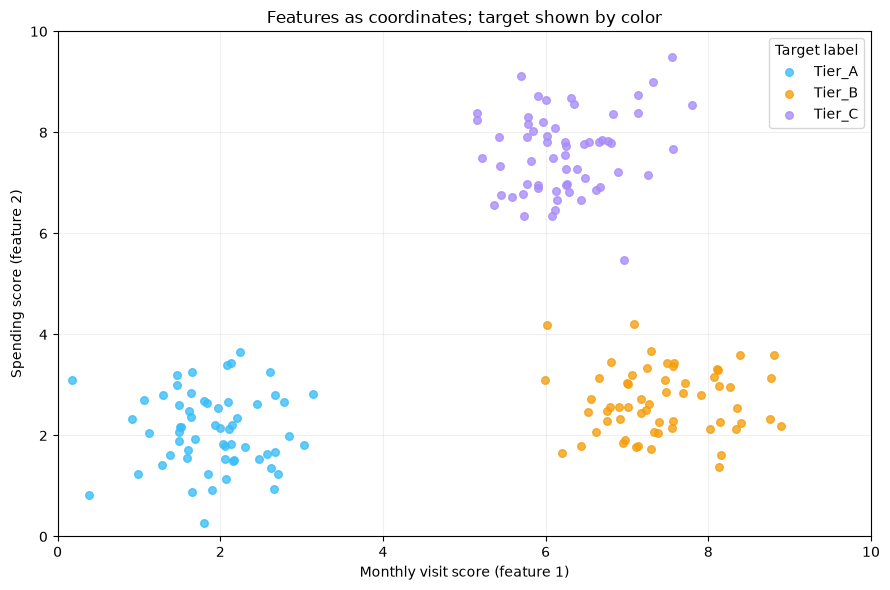

In [8]:
fig, ax = plt.subplots(figsize=(9, 6))
for class_name in CLASS_NAMES:
    mask = customer_df[TARGET_COLUMN] == class_name
    ax.scatter(
        customer_df.loc[mask, "monthly_visit_score"],
        customer_df.loc[mask, "spending_score"],
        s=30,
        alpha=0.78,
        color=CLASS_COLORS[class_name],
        label=class_name,
    )

ax.set_title("Features as coordinates; target shown by color")
ax.set_xlabel("Monthly visit score (feature 1)")
ax.set_ylabel("Spending score (feature 2)")
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.grid(alpha=0.2)
ax.legend(title="Target label")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "features_and_target.png", dpi=160, bbox_inches="tight")
plt.show()

## 8. What is a label?

In a classification task, the known category for one example is commonly called its **label**.

For our dataset:

- `Tier_A` is one label;
- `Tier_B` is another label;
- `Tier_C` is another label.

You will often hear **target** and **label** used in related ways. In many machine-learning explanations, “label” means the correct answer attached to a supervised example. “Target” often refers to the target variable/column `y`. Terminology can vary between libraries and teams, so always check how a project uses the words.

In [9]:
print("Examples of target labels:")
print(y_names.value_counts())

Examples of target labels:
customer_segment
Tier_A    60
Tier_B    60
Tier_C    60
Name: count, dtype: int64


### Convert readable labels into class IDs

A PyTorch classification loss usually expects class targets as integer IDs. We create a mapping from category names to IDs:

- `Tier_A` → `0`
- `Tier_B` → `1`
- `Tier_C` → `2`

These numbers are **identifiers**, not measurements. Class `2` is not “twice as much” as class `1`, and the values do not create a meaningful ranking by themselves.

In [10]:
class_to_id = {name: index for index, name in enumerate(CLASS_NAMES)}
id_to_class = {index: name for name, index in class_to_id.items()}

y_encoded = y_names.map(class_to_id).astype("int64")

print("Label mapping:", class_to_id)
print("Readable labels:", y_names.head(6).tolist())
print("Encoded labels: ", y_encoded.head(6).tolist())

Label mapping: {'Tier_A': 0, 'Tier_B': 1, 'Tier_C': 2}
Readable labels: ['Tier_A', 'Tier_A', 'Tier_A', 'Tier_A', 'Tier_A', 'Tier_A']
Encoded labels:  [0, 0, 0, 0, 0, 0]


## 9. Targets are not always category labels

The kind of target depends on the question:

- **Classification:** predict a category, such as `Tier_A`, `Tier_B`, or `Tier_C`. The target is categorical; its class label is often encoded as an integer ID for training.
- **Regression:** predict a numeric value, such as a house price. The target is a number, not a class ID.

The word “label” is sometimes used broadly for supervised answers, including numeric answers. In this series, we will usually say **class label** when discussing classification and **numeric target** when discussing regression so the distinction stays clear.

In [11]:
# A tiny conceptual house-price table: no model is trained in this section.
house_examples = pd.DataFrame(
    {
        "area_m2": [75, 110, 145],
        "bedrooms": [2, 3, 4],
        "price_usd": [185_000, 278_000, 365_000],
    }
)

display(house_examples)

print("For a house-price regression task:")
print("Features:", ["area_m2", "bedrooms"])
print("Numeric target:", "price_usd")

,area_m2,bedrooms,price_usd
0,75,2,185000
1,110,3,278000
2,145,4,365000


For a house-price regression task:
Features: ['area_m2', 'bedrooms']
Numeric target: price_usd


## 10. Why the target must be separated from the features

Imagine training a model to predict `customer_segment` while also including `customer_segment` in the input columns. The answer would already be inside the input. That would not teach the model to infer the category from customer behavior.

For this task:

- `X` contains the information available to make a prediction;
- `y` contains the answer used during supervised training;
- at prediction time, we provide new feature values, not the unknown target.

Also, `customer_id` is only a record identifier in this example. We keep it in the table so we can trace rows, but do not include it in `X`.

In [12]:
# Explicitly define the model input columns and target column.
X_df = customer_df[FEATURE_COLUMNS].copy()
y_names = customer_df[TARGET_COLUMN].copy()

assert TARGET_COLUMN not in X_df.columns
assert "customer_id" not in X_df.columns
assert len(X_df) == len(y_names)

print("Input columns:", X_df.columns.tolist())
print("Target column:", TARGET_COLUMN)
print("Number of aligned examples:", len(X_df))

Input columns: ['monthly_visit_score', 'spending_score']
Target column: customer_segment
Number of aligned examples: 180


## 11. Convert the prepared data into PyTorch tensors

PyTorch models work with tensors. For this small classification example:

- feature values become a floating-point tensor (`float32`);
- class IDs become an integer tensor (`int64` / `long`).

The feature tensor has shape `(examples, features)`. The target tensor has one class ID per example.

In [13]:
X_tensor = torch.tensor(X_df.to_numpy(), dtype=torch.float32, device=DEVICE)
y_tensor = torch.tensor(y_encoded.to_numpy(), dtype=torch.long, device=DEVICE)

print("X_tensor shape:", tuple(X_tensor.shape))
print("X_tensor dtype:", X_tensor.dtype)
print("y_tensor shape:", tuple(y_tensor.shape))
print("y_tensor dtype:", y_tensor.dtype)

X_tensor shape: (180, 2)
X_tensor dtype: torch.float32
y_tensor shape: (180,)
y_tensor dtype: torch.int64


## 12. A PyTorch Dataset and DataLoader

There are two related meanings of “dataset” to understand:

1. In everyday machine-learning language, a dataset is the collection of examples.
2. In PyTorch, a `Dataset` object is a Python object that provides examples to the training code. `TensorDataset` is a convenient built-in class that pairs tensors row by row.

A `DataLoader` can retrieve those examples in small groups called **batches**. We are only previewing the idea here; training/validation/test splitting and more complete input pipelines come later.

In [14]:
customer_dataset = TensorDataset(X_tensor, y_tensor)
customer_loader = DataLoader(
    customer_dataset,
    batch_size=8,
    shuffle=True,
)

print("Number of examples in Dataset:", len(customer_dataset))
print("Number of batches in this DataLoader:", len(customer_loader))

Number of examples in Dataset: 180
Number of batches in this DataLoader: 23


### Inspect one batch

Each batch contains a group of feature rows and the matching target IDs. Notice that the first dimension is now the batch size, not the total dataset size.

In [15]:
batch_features, batch_targets = next(iter(customer_loader))

print("Batch features shape:", tuple(batch_features.shape))
print("Batch targets shape:", tuple(batch_targets.shape))
print("First feature row in this batch:", batch_features[0].tolist())
print("Matching target ID:", int(batch_targets[0]))
print("Matching target name:", id_to_class[int(batch_targets[0])])

Batch features shape: (8, 2)
Batch targets shape: (8,)
First feature row in this batch: [1.2952979803085327, 2.809767484664917]
Matching target ID: 0
Matching target name: Tier_A


## 13. What changes for unsupervised learning?

In Lesson 2.1.2, we compared supervised learning with unsupervised learning.

For the supervised classification task, we use both:

- `X`: feature values;
- `y`: known target labels.

For an unsupervised clustering task, we provide the feature values but do **not** provide the target labels to the clustering algorithm. The algorithm searches for structure using the inputs it receives.

The target column may still exist in a research or teaching table, but we must not pass it to an unsupervised method when the task is to discover structure without supplied labels.

In [16]:
# This is the data an unsupervised clustering algorithm would receive.
X_for_clustering = X_tensor

# The target labels remain separate for later interpretation only.
# Do not pass y_tensor into the clustering algorithm.
print("Unsupervised input shape:", tuple(X_for_clustering.shape))
print("Target labels supplied to clustering: No")

Unsupervised input shape: (180, 2)
Target labels supplied to clustering: No


## 14. Export the prepared data and lesson facts

We export the customer table and a small JSON summary. These artifacts can be reused by the separate Manim video project so the animations use the same rows, column names, label mapping, and shapes as this notebook.

In [17]:
customer_df.to_csv(OUTPUT_DIR / "customer_dataset.csv", index=False)

results = {
    "lesson": "2.1.3",
    "title": "Understand Features, Targets, Datasets, and Labels",
    "seed": SEED,
    "device": str(DEVICE),
    "number_of_examples": int(len(customer_df)),
    "dataset_columns": customer_df.columns.tolist(),
    "feature_columns": FEATURE_COLUMNS,
    "target_column": TARGET_COLUMN,
    "feature_shape": list(X_tensor.shape),
    "target_shape": list(y_tensor.shape),
    "feature_dtype": str(X_tensor.dtype),
    "target_dtype": str(y_tensor.dtype),
    "label_mapping": class_to_id,
    "label_counts": {str(k): int(v) for k, v in y_names.value_counts().items()},
    "first_examples": customer_df.head(5).round(3).to_dict(orient="records"),
    "representative_examples": customer_df.iloc[[0, samples_per_group, samples_per_group * 2]].round(3).to_dict(orient="records"),
    "batch_size": 8,
    "first_batch_feature_shape": list(batch_features.shape),
    "first_batch_target_shape": list(batch_targets.shape),
    "regression_example": {
        "features": ["area_m2", "bedrooms"],
        "numeric_target": "price_usd",
    },
}

with open(OUTPUT_DIR / "lesson_results.json", "w", encoding="utf-8") as file:
    json.dump(results, file, indent=2, ensure_ascii=False)

print("Exported:", OUTPUT_DIR / "customer_dataset.csv")
print("Exported:", OUTPUT_DIR / "lesson_results.json")

Exported: d:\AI\Assignment\machine-learning\module1\phase-2-lesson-2.1.3-features-targets-datasets-labels\outputs\customer_dataset.csv
Exported: d:\AI\Assignment\machine-learning\module1\phase-2-lesson-2.1.3-features-targets-datasets-labels\outputs\lesson_results.json


## 15. Knowledge check — explain the data before using a model

Before training any model, try to answer these questions in your own words:

1. What does one row represent?
2. Which columns are features for the customer-segment prediction task?
3. Which column is the target?
4. Why is `customer_id` excluded from the model inputs in this example?
5. What is the difference between a readable class label and its integer class ID?
6. Why does a house-price task have a numeric target rather than a class label?
7. Which values would you provide to a clustering algorithm if you wanted it to find groups without supplied labels?

### Small coding challenge

Change `FEATURE_COLUMNS` to use only `monthly_visit_score`. Rebuild `X_df` and inspect its shape. Then restore both features and verify that the target remains separate.

In [18]:
# Challenge starter: change this list and run the cell again.
challenge_feature_columns = ["monthly_visit_score"]
X_challenge = customer_df[challenge_feature_columns]

print("Challenge feature columns:", challenge_feature_columns)
print("Challenge X shape:", X_challenge.shape)
print("Target remains separate:", TARGET_COLUMN not in X_challenge.columns)

Challenge feature columns: ['monthly_visit_score']
Challenge X shape: (180, 1)
Target remains separate: True


## 16. Recap: the vocabulary of a machine-learning dataset

| Term | Meaning in this lesson | Our example |
|---|---|---|
| Dataset | Collection of examples | All 180 customer rows |
| Example / sample | One observation | One customer row |
| Feature | Input used for prediction | Visit score, spending score |
| Target | Value we want to predict | Customer segment |
| Label | Known category for a classification example | Tier_A, Tier_B, Tier_C |
| `X` | Feature matrix | 180 × 2 numeric values |
| `y` | Target vector | 180 class IDs |

**The habit to remember:** define the prediction question first, then identify which columns are inputs (`X`) and which column is the answer (`y`).

### Coming next — Lesson 2.1.4

**Training, Validation, and Test Sets:** we will learn why we should not judge a model only on the examples it learned from, and how to keep separate data for a more reliable check.